# Describing Data

### What do you find in this notebook?

In this exercise, first, you will familiarize yourself with the Python libraries 'statsmodels' and 'SciPy' that let you do statistical analysis: calculate descriptive statistics, sample datapoints, study relationships between variables, and perform hypothesis testing. Then, second, you will work on a set of exercises that will let you practice your skills.

Here we show a couple of examples of how to do common analyses, but there are many more useful probability distributions and statistical tests. In the linked documentation, you will find complete information, and a lot more details compared to what is outlined in this notebook:
- [statsmodels](https://www.statsmodels.org/stable/examples/index.html), [more complete documentation](https://www.statsmodels.org/stable/stats.html)
- [SciPy](https://docs.scipy.org/doc/scipy/reference/stats.html)

# Tutorial: How to use the libraries

- You will be working with the full US 2015 census dataset (acs2015_county_data.csv, available at https://www.kaggle.com/muonneutrino/us-census-demographic-data#acs2015_county_data.csv). Here we load it. Take some time to familiarize yourself with the contents. One row represents one county.

In [716]:
import pandas as pd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import math

#load the statistical libraries
from statsmodels.stats import diagnostic
from scipy import stats

In [717]:
data_folder = './data/'
df = pd.read_csv(data_folder + 'acs2015_county_data.csv')

In [718]:
df.columns

Index(['CensusId', 'State', 'County', 'TotalPop', 'Men', 'Women', 'Hispanic',
       'White', 'Black', 'Native', 'Asian', 'Pacific', 'Citizen', 'Income',
       'IncomeErr', 'IncomePerCap', 'IncomePerCapErr', 'Poverty',
       'ChildPoverty', 'Professional', 'Service', 'Office', 'Construction',
       'Production', 'Drive', 'Carpool', 'Transit', 'Walk', 'OtherTransp',
       'WorkAtHome', 'MeanCommute', 'Employed', 'PrivateWork', 'PublicWork',
       'SelfEmployed', 'FamilyWork', 'Unemployment'],
      dtype='str')

In [719]:
df.sample(10)

,CensusId,State,County,TotalPop,Men,Women,Hispanic,White,Black,Native,...,Walk,OtherTransp,WorkAtHome,MeanCommute,Employed,PrivateWork,PublicWork,SelfEmployed,FamilyWork,Unemployment
1090,21195,Kentucky,Pike,63434,31019,32415,0.8,97.2,0.9,0.1,...,2.7,0.9,2.2,24.5,20861,76.3,19.3,4.4,0.1,10.7
1767,33007,New Hampshire,Coos,31870,16226,15644,1.5,94.4,1.7,0.6,...,3.5,1.0,5.8,20.7,14644,72.7,18.0,9.0,0.4,6.9
2223,41031,Oregon,Jefferson,22061,11313,10748,19.6,60.6,0.9,15.8,...,4.0,3.0,4.0,19.7,8167,69.9,23.3,6.7,0.1,14.4
1014,21043,Kentucky,Carter,27326,13502,13824,1.2,96.7,0.8,0.2,...,4.9,0.6,2.3,31.4,10039,80.1,15.5,4.3,0.1,11.1
1459,28117,Mississippi,Prentiss,25380,12413,12967,1.3,83.3,14.2,0.0,...,1.6,0.4,1.4,24.5,9559,76.7,15.3,8.0,0.0,10.2
2378,46035,South Dakota,Davison,19787,9961,9826,2.2,92.4,0.5,3.2,...,4.2,0.9,4.3,13.8,10359,79.9,12.7,7.2,0.3,3.3
893,20011,Kansas,Bourbon,14812,7324,7488,2.3,91.0,3.5,0.8,...,2.5,0.4,5.4,17.9,6541,75.8,18.3,5.8,0.1,3.3
2073,39061,Ohio,Hamilton,804194,386561,417633,2.8,66.8,25.6,0.1,...,2.9,1.0,4.1,23.0,383555,84.8,10.4,4.7,0.1,8.8
2307,42127,Pennsylvania,Wayne,51642,27420,24222,4.0,91.1,3.2,0.2,...,2.3,0.8,5.7,30.3,21211,77.4,13.7,8.7,0.2,7.8
1440,28079,Mississippi,Leake,23153,11588,11565,4.2,48.0,41.4,5.8,...,2.0,0.5,1.2,31.4,8537,74.5,19.3,6.2,0.0,10.5


- We will focus first on income per capita across counties.

<Axes: >

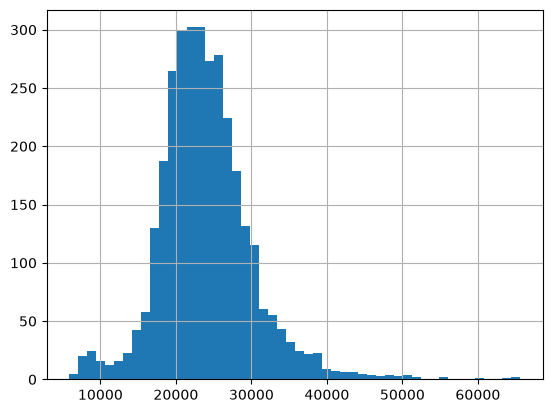

In [720]:
df['IncomePerCap'].hist(bins = 50)

### 1. Calculating descriptive statisctics

- Let's calculate basic descriptive statistics of the income per capita.

In [721]:
df['IncomePerCap'].describe()

count     3220.000000
mean     23981.771739
std       6204.339960
min       5878.000000
25%      20238.500000
50%      23460.000000
75%      27053.250000
max      65600.000000
Name: IncomePerCap, dtype: float64

- What distribution does the data come from? Here is how we can test the goodness of the fit.

In [722]:
# does the data come from a normal distrbution?
diagnostic.kstest_normal(df['IncomePerCap'].values, dist = 'norm')

(np.float64(0.0637621121184162), np.float64(0.0009999999999998899))

- p_value < 0.05 -> we can reject the null hypothesis that the data comes from a normal distribution!

In [723]:
#how about exponential?
diagnostic.kstest_normal(df['IncomePerCap'].values, dist = 'exp')

(np.float64(0.433243770582646), np.float64(0.0009999999999998899))

- p < 0.05 -> not exponential either!

### 2. How to sample the data

- Often we need to find random samples from the dataset. We can do so conveniently with pandas wrappers.

In [724]:
#make 10 samples with replacement
sample1_counties = df.sample(n = 10, replace = True)

#make 10 samples without replacement
sample1_counties = df.sample(n = 10, replace = False)

#sometimes we want to sample in an ublanaced way, so that we upsample datapoints of certain characteristic,
#and downsample the others. this can be acieved with weights parameter
#here we sample by upsampling counties with large population
sample2_counties = df.sample(n = 10, replace = False, weights = df['TotalPop'])

In [725]:
#on avergage, the samples in the sample produce with reveighting now have higher population, as we wanted!
print(sample1_counties['TotalPop'].mean())
print(sample2_counties['TotalPop'].mean())

26388.5
729586.6


### 3. Examining relationship between two variables

first value is the correlation coefficient: ±1 correlation strength (+1 means that when one variable goes up, the other goes up. -1 means one goes down as the other goes up)

the second value is the p value: the probability of seeing a correlation at least this strong if the true correlation were 0

- Is income per capita of a county correlated with the unemployment?

In [726]:
stats.pearsonr(df['IncomePerCap'],df['Employed'])

PearsonRResult(statistic=np.float64(0.26461363203944865), pvalue=np.float64(9.942215354243078e-53))

Pearson (r) measures how well the points fit a straight line. It’s sensitive to outliers and to skewed data.

- There is a small (0.26), but significant (p < 0.05) positive correlation.

In [727]:
stats.spearmanr(df['IncomePerCap'],df['Employed'])

SignificanceResult(statistic=np.float64(0.30770631560595474), pvalue=np.float64(1.4152964311737174e-71))

Spearman (ρ) first replaces each value with its rank, then computes Pearson on the ranks. It measures whether the relationship is monotonic, meaning one variable consistently rises or falls with the other, even if not in a straight line. It’s robust to outliers and skew.

- Spearman rank coorrelation is also significant.

### 4. Hypothesis testing

- Is income per capita higher in New York counties compared to California counties?

In [728]:
df.loc[df['State'] == 'New York']['IncomePerCap'].mean()

np.float64(28189.75806451613)

In [729]:
df.loc[df['State'] == 'California']['IncomePerCap'].mean()

np.float64(27902.603448275862)

- We see that there is a ~300$ gap. Quite a lot!
- But is it significantly higher? Let's use a t-test. This is a two-sided test for the null hypothesis that the two independent samples have identical average (expected) values. 

In [730]:
stats.ttest_ind(df.loc[df['State'] == 'New York']['IncomePerCap'], df.loc[df['State'] == 'California']['IncomePerCap'])

TtestResult(statistic=np.float64(0.19788117232375713), pvalue=np.float64(0.8434785239169611), df=np.float64(118.0))

- p is not smaller than 0.05 -> we cannot reject the null hypothesis that the income is the same -> there is no significant difference

### 5. How to measure uncertainty
- Now we see the importance of mesuring uncertainty and indicating it on data visualizations.
- Visual inspection of 95% confidence intervals lets us see that the difference is not significant (the errorbars are overlapping).

(25000.0, 32000.0)

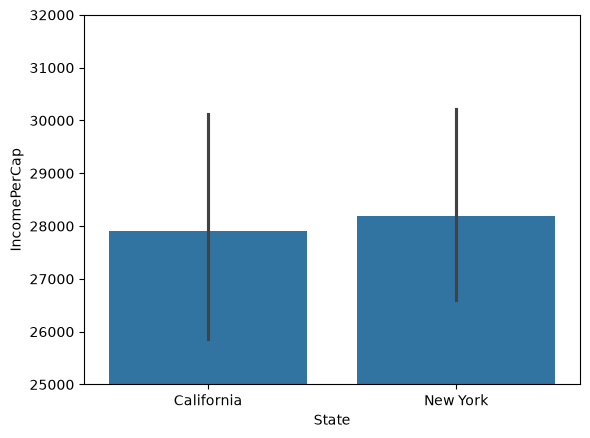

In [731]:
ax = sns.barplot(x="State", y="IncomePerCap", data=df.loc[df['State'].isin(['New York','California'])])
plt.ylim([25000,32000])

In [732]:
from IPython.display import display

# Exercise 1: Boosting the economy by incentivizing self-employment

Assume the biggest priority of the local government in 2018 is to increase per-capita income. To do so, the officials plan to adopt a strategy for incentivizing self-employment through a series of campaigns, educational programs, and dedicated funds.

Since it is unethical and impossible in this setting to run a controlled experiment involving citizens (e.g., fire employees and force them to self-employ), the officials have asked you, the data scientist, to establish the effect of self-employment on the economy, relying on observational data.

**A)** Using suitable methods, determine and quantify the dependency between the percentage of self-employed citizens and per capita income across all 3,212 US counties. Do citizens in counties that have a higher percentage of self-employed people earn more per capita?

<class 'pandas.DataFrame'>
RangeIndex: 3220 entries, 0 to 3219
Data columns (total 37 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CensusId         3220 non-null   int64  
 1   State            3220 non-null   str    
 2   County           3220 non-null   str    
 3   TotalPop         3220 non-null   int64  
 4   Men              3220 non-null   int64  
 5   Women            3220 non-null   int64  
 6   Hispanic         3220 non-null   float64
 7   White            3220 non-null   float64
 8   Black            3220 non-null   float64
 9   Native           3220 non-null   float64
 10  Asian            3220 non-null   float64
 11  Pacific          3220 non-null   float64
 12  Citizen          3220 non-null   int64  
 13  Income           3219 non-null   float64
 14  IncomeErr        3219 non-null   float64
 15  IncomePerCap     3220 non-null   int64  
 16  IncomePerCapErr  3220 non-null   int64  
 17  Poverty          3220 non

0       24974
1       27317
2       16824
3       18431
4       20532
        ...  
3215     9102
3216     8821
3217     8420
3218     7960
3219     7743
Name: IncomePerCap, Length: 3220, dtype: int64

0        5.5
1        5.8
2        7.3
3        6.7
4        4.2
        ... 
3215     4.1
3216    13.6
3217    13.1
3218     7.3
3219     4.4
Name: SelfEmployed, Length: 3220, dtype: float64

PearsonRResult(statistic=np.float64(0.08727386609551786), pvalue=np.float64(7.052861196524552e-07))
SignificanceResult(statistic=np.float64(0.056413673053189874), pvalue=np.float64(0.0013623847564714563))


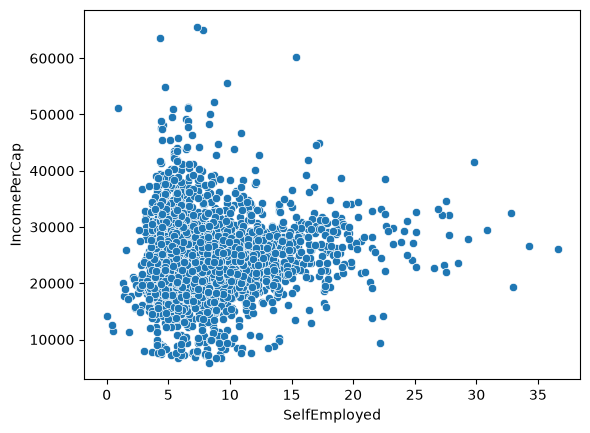

In [733]:
# we can look if there is a significant correlation between self employment and salary per capita

# first looking at the variables and plotting
df.info()
display(df["IncomePerCap"])
display(df["SelfEmployed"])

sns.scatterplot(x=df["SelfEmployed"], y=df["IncomePerCap"])

# the data seems to have a decent amount of outliers and IncomePerCap is right skewed
# so Spearman to evaluate correlation is the more robust choice over Pearson
"""
Computing both still tells you something:

r ≈ ρ: the relationship is roughly linear and not driven by outliers.
r and ρ clearly differ: outliers or a non-linear shape are affecting Pearson.
"""
print(stats.pearsonr(df['SelfEmployed'], df['IncomePerCap']))
print(stats.spearmanr(df['SelfEmployed'], df['IncomePerCap']))


_Do citizens in counties that have a higher percentage of self-employed people earn more per capita?_

The coefficients are positive and very close to 0 and the p value much smaller than 0.05. This indicates that there is a very small positive relationship between self employment and income. However, this correlation is negligible as it is so small and significance is mainly due to the high amount of samples.

Across all counties, there is no meaningful dependency.

**B)** The pilot program will involve all counties within a limited set of three US states. Set A includes Wisconsin, Tennessee, and  Minnesota. Quantify the dependency of per-capita income on self-employment rates across all the counties in set A.

PearsonRResult(statistic=np.float64(-0.202293507365215), pvalue=np.float64(0.001188163932213867))
SignificanceResult(statistic=np.float64(-0.2366979000103385), pvalue=np.float64(0.0001401009031365511))


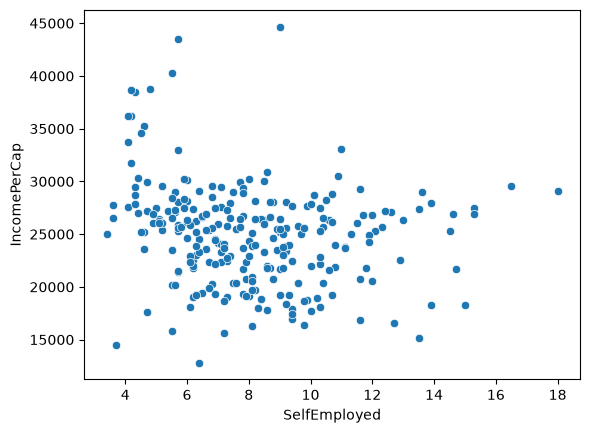

In [734]:
#filtering df to get set A
set_A = df.loc[df['State'].isin(['Wisconsin', 'Tennessee', 'Minnesota'])]

#now we can apply thre same analysis as before but for set A instead of df

#plotting
sns.scatterplot(x=set_A["SelfEmployed"], y=set_A["IncomePerCap"])

#using both Pearson and Spearman to determine correlation
print(stats.pearsonr(set_A['SelfEmployed'], set_A['IncomePerCap']))
print(stats.spearmanr(set_A['SelfEmployed'], set_A['IncomePerCap']))


The scatterplot looks similar to the one for all counties. Pearson and Spearman give close values, both showing a weak negative correlation between self-employment and income per capita, with p-values well below 0.05. Unlike for all counties, the relationship is negative: counties in set A with more self-employment tend to have a lower income per capita. Since set A only has 254 counties, the significance is not just a consequence of a large sample size.

So, whereas for all counties there is no meaningful dependency, for set A there is a weak but non-negligible, significant negative correlation between self-employment and income per capita.

**Correlation strength (Cohen's convention, applies to |r| or |ρ|)**

| \|r\| | Strength |
|---|---|
| < 0.1 | negligible |
| 0.1 – 0.3 | weak (small) |
| 0.3 – 0.5 | moderate (medium) |
| > 0.5 | strong (large) |

Only a convention: always report the value along with the label. The sign gives the direction (+ or −), the magnitude gives the strength.

**C)** In which state within set A is the observed effect of self-employment on per-capita income the strongest?

PearsonRResult(statistic=np.float64(-0.202293507365215), pvalue=np.float64(0.001188163932213867))
SignificanceResult(statistic=np.float64(-0.2366979000103385), pvalue=np.float64(0.0001401009031365511))
Wisconsin 72 counties
PearsonRResult(statistic=np.float64(-0.32905300016378525), pvalue=np.float64(0.004768134887745218))
SignificanceResult(statistic=np.float64(-0.46351291044049403), pvalue=np.float64(4.124859155565999e-05))

Tennessee 95 counties
PearsonRResult(statistic=np.float64(-0.23836048684913147), pvalue=np.float64(0.02001163195552821))
SignificanceResult(statistic=np.float64(-0.316991392780988), pvalue=np.float64(0.0017487582457931458))

Minnesota 87 counties
PearsonRResult(statistic=np.float64(-0.25385519216540625), pvalue=np.float64(0.01766519930091198))
SignificanceResult(statistic=np.float64(-0.21107460598245847), pvalue=np.float64(0.04970805582462063))



<Axes: xlabel='SelfEmployed', ylabel='IncomePerCap'>

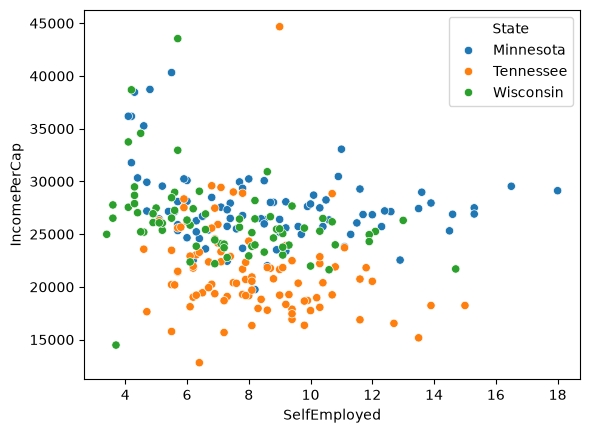

In [735]:
#using both Pearson and Spearman to determine correlation for set_A
print(stats.pearsonr(set_A['SelfEmployed'], set_A['IncomePerCap']))
print(stats.spearmanr(set_A['SelfEmployed'], set_A['IncomePerCap']))

#for loop to avoid writing the same lines three times (same filtering and analysis)
for state in ['Wisconsin', 'Tennessee', 'Minnesota']:
    state_df = df.loc[df['State'] == state] #filtering to get counties from one state
    print(state, len(state_df), "counties")
    print(stats.pearsonr(state_df['SelfEmployed'], state_df['IncomePerCap']))
    print(stats.spearmanr(state_df['SelfEmployed'], state_df['IncomePerCap']))
    print("")

# Plot the states together, coloured by state, to compare them visually
sns.scatterplot(data=set_A, x='SelfEmployed', y='IncomePerCap', hue='State')

In all three states, the correlation between self-employment and income per capita is negative and significant (p < 0.05), although Minnesota's Spearman p-value (0.0497) is only borderline significant.

The strongest correlation (for both |r| and |ρ|) is in Wisconsin. According to Cohen's convention it's moderate. For Tennessee and Minnesota it's weak.

So the observed effect of self-employment on per-capita income is strongest (most negative) in Wisconsin.

**D)** Set B includes New Jersey, Kansas, and Rhode Island. Repeat the analysis from steps B and C above, but now for set B. In which of the two sets A and B (if any) would you recommend incentivizing self-employment? Explain your reasoning. Hint: It is useful to add a notion of confidence to your results and explore the data visually.

PearsonRResult(statistic=np.float64(-0.2322214134608569), pvalue=np.float64(0.007607493042857458))
SignificanceResult(statistic=np.float64(-0.16010624610827853), pvalue=np.float64(0.0677389077477531))
---
New Jersey 21 counties
PearsonRResult(statistic=np.float64(0.4804478471336282), pvalue=np.float64(0.027488944757806208))
SignificanceResult(statistic=np.float64(0.40403460177366013), pvalue=np.float64(0.06929493068926955))

Kansas 105 counties
PearsonRResult(statistic=np.float64(0.2581029971443692), pvalue=np.float64(0.007853351846832522))
SignificanceResult(statistic=np.float64(0.28392575483491556), pvalue=np.float64(0.0033332825399419908))

Rhode Island 5 counties
PearsonRResult(statistic=np.float64(0.9021788382149805), pvalue=np.float64(0.03618310201575915))
SignificanceResult(statistic=np.float64(0.9999999999999999), pvalue=np.float64(1.4042654220543602e-24))



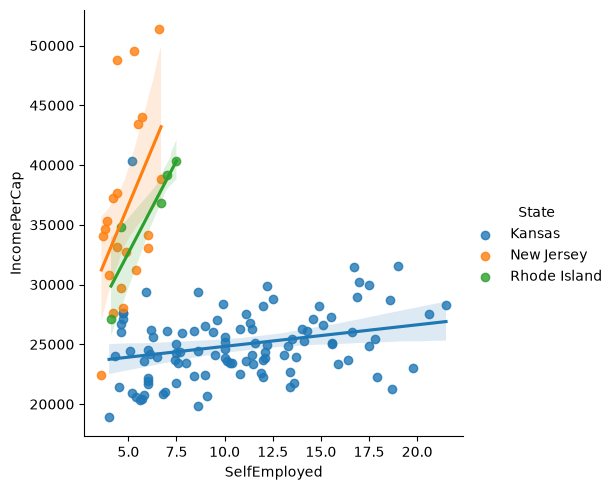

In [736]:
#filtering df to get set B
set_B = df.loc[df['State'].isin(['New Jersey', 'Kansas', 'Rhode Island'])]

#using both Pearson and Spearman to determine correlation for set_B
print(stats.pearsonr(set_B['SelfEmployed'], set_B['IncomePerCap']))
print(stats.spearmanr(set_B['SelfEmployed'], set_B['IncomePerCap']))
print("---")
#plotting: regression line + 95% confidence band per state
sns.lmplot(data=set_B, x='SelfEmployed', y='IncomePerCap', hue='State')

#filtering and analysis for each of the 
for state in ['New Jersey', 'Kansas', 'Rhode Island']:
    state_df = df.loc[df['State'] == state] #filtering to get counties from one state
    print(state, len(state_df), "counties")
    print(stats.pearsonr(state_df['SelfEmployed'], state_df['IncomePerCap']))
    print(stats.spearmanr(state_df['SelfEmployed'], state_df['IncomePerCap']))
    print("")

Set B as a whole shows a negative correlation, but each state on its own shows a positive one (Simpson's paradox). Since the policy applies within states, the per-state results matter.

Confidence varies: Rhode Island (5 counties) and New Jersey (21 counties) are not reliable, but Kansas (105 counties) shows a weak, significant positive correlation.

I would recommend set B, mainly Kansas, and not set A (negative correlation in all three states). This remains a cautious recommendation, since correlation does not prove causation.

# Exercise 2. Data visualization and read the stats comprehension and interpretation questions.

- As part of the quizes, two homeworks and the final exam, you will be at times asked to interpret your result based on the understanding of underlying concepts. The questions below can help you practice and get a sense of how well you understand the concepts covered in the class so far. Can you answer these questions confidently?

### Question 1. The yearly salaries (in thousands of CHF) of 7000 people are summarized in the following box plot. If the 20th percentile of the salaries is 110,000, how many people earn between 110,000 and 114,000?

- a) 2100
- b) 700
- c) 350
- d) 70

<img src="boxplot.png" style="width: 400px;" align="left"/>

| Percentile | Other name | Where on the box plot |
|---|---|---|
| 25th | Q1 (first quartile) | left edge of the box |
| 50th | median | line inside the box |
| 75th | Q3 (third quartile) | right edge of the box |

In [737]:
# 114'000 is at 25 percentile => 25-20= 5% of people lie between 110'000 and 114'000
# 5% of 7000 = 0.05*7000 = 350 people

#c)

### Question 2. What visualizations are suitable for getting insights about the distribution of a single continuous variable?

- a) Barplot and histogram
- b) Boxplot and histogram
- c) Scatterplot and boxplot
- d) Barplot, boxplot, and histogram

**Continuous:** the variable can take any value in a range, including decimals. Examples: income, height, salary, commute time.

The opposite of continuous is **categorical**: a variable that takes a limited set of labels, e.g. State, genre or studio. A **discrete** numeric variable like "number of children" sits in between, but it's often treated like a continuous one when it has many possible values.

In [738]:
# b)

### Question 3. In a new groundbreaking study, 28 out of 100 patients reported improvements after taking a new medicine. It is known that, when given a placebo, 20% of the patients report feeling better. What is the p-value assuming the null hypothesis that the probability of successful treatment in this groundbreaking study is the same as the probability of reporting feeling better under placebo, according to a one-sided binomial test? Hint: you may use the statsmodels.stats.proportion.binom_test function.

- a) 0.00034
- b) 0.0034
- c) 0.034
- d) 0.34

In [739]:
# c) (just by guessing)

#code anyway
from statsmodels.stats.proportion import binom_test

# 28 successes out of 100 patients, null hypothesis: p = 0.2 (placebo rate)
# one-sided: is the success rate LARGER than 0.2?
binom_test(count=28, nobs=100, prop=0.2, alternative='larger')

np.float64(0.03415162963907479)

### Question 4. The 95% confidence interval of the average height of 1000 people using bootstrap resampling with 10000 bootstrap samples is calculated by:

- a) Sampling 1000 height values with replacement and computing the mean. This is repeated 10000 times to create a sorted list of the 10000 means. The CI is defined by the 500th and the 9500th value in sorted order.
- b) Sampling 10000 height values without replacement and computing the mean. This is repeated 1000 times to create a sorted list of the 1000 means. The CI is defined by the 25th and the 975th value in sorted order.
- c) Sampling 1000 height values with replacement and computing the mean. This is repeated 10000 times to create a sorted list of the 10000 means. The CI is defined by the 250th and the 9750th value in sorted order.
- d) Sampling 1000 height values without replacement and computing the mean. This is repeated 10000 times to create a sorted list of the 10000 means. The CI is defined by the 500th and the 9500th value in sorted order.

### Implement your bootstrapping function that you will use in the rest of the course. It should take an array and the number of iterations as inputs, and output 95% confidence intervals of the mean.

In [740]:
# c) (a is a trap, it's 2.5% on each side)

In [741]:
# bootstrap function, which follows the steps of answer c)

def bootstrap_CI(data, nbr_draws):
    data = np.asarray(data)        # works for lists, numpy arrays and pandas Series
    means = np.zeros(nbr_draws)    # empty array to store one mean per bootstrap sample

    for i in range(nbr_draws):
        # resample WITH replacement, same size as the original data
        sample = np.random.choice(data, size=len(data), replace=True)
        means[i] = np.mean(sample)

    # 95% CI: cut 2.5% off each end of the distribution of means
    return [np.percentile(means, 2.5), np.percentile(means, 97.5)]

### Question 5. A study conducted at EPFL revealed a negative Spearman’s correlation between GPA and entry-level job salary. Which of the following statements is true?

- a) There could be a positive Spearman’s correlation between GPA and entry-level job salary in every single department of EPFL.
- b) Spearman correlation between GPA and entry-level job salary in every single department has to be positive.
- c) Across all levels, as opposed to entry-level only, higher GPA scores are associated with higher job salaries.
- d) We can infer that finishing EPFL with a higher GPA causes you to have a lower entry-level job salary.

In [742]:
# a) (Simpson's paradox)

### Question 6. The average number of requests per page during a day on a large website is 200, while the median is 15. 

- a) You can assume that the distribution is heavy-tailed.
- b) You are dealing with a left-skewed distribution.
- c) Half of the pages get more than 200 requests.
- d) None of the above.

In [743]:
# a)